# Smart Inventory — ML Model Training

This notebook trains and compares machine-learning models for demand forecasting.

## Models
1. Naive baseline reference
2. Random Forest Regressor
3. XGBoost Regressor
4. LightGBM Regressor
5. CatBoost Regressor

The time-series baselines are evaluated separately in `05_Time_Series_Baselines.ipynb`.

## Evaluation
We use the already-created chronological:
- Training set
- Validation set
- Test set

The test set is **not used for model selection or tuning**.

Primary metrics:
- MAE
- RMSE
- R²

In [1]:
import numpy as np
import pandas as pd
import joblib
import warnings

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load prepared datasets

In [2]:
models_dir = Path("../Models")

X_train = np.load(models_dir / "X_train.npy")
X_val = np.load(models_dir / "X_val.npy")
X_test = np.load(models_dir / "X_test.npy")

y_train = np.load(models_dir / "y_train.npy")
y_val = np.load(models_dir / "y_val.npy")
y_test = np.load(models_dir / "y_test.npy")

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val:  ", y_val.shape)
print("y_test: ", y_test.shape)

X_train: (49200, 61)
X_val:   (10500, 61)
X_test:  (10600, 61)

y_train: (49200,)
y_val:   (10500,)
y_test:  (10600,)


## 2. Evaluation function

In [3]:
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

results = []

## 3. Simple ML baseline

Before complex models, use the validation/test predictions from the simplest useful feature: `Lag_1`.

Because the saved arrays contain encoded features, we will use the `Lag_1` column from the original feature data only for reference later. This notebook's primary comparison starts with the ML models below.

In [4]:
print("Prepared ML datasets loaded.")
print("Target mean:", y_train.mean())
print("Target standard deviation:", y_train.std())

Prepared ML datasets loaded.
Target mean: 136.35924796747966
Target standard deviation: 109.08784754292418


## 4. Random Forest Regressor

In [5]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)

rf_val_pred = rf_model.predict(X_val)
rf_test_pred = rf_model.predict(X_test)

rf_val_metrics = evaluate_model(
    "Random Forest - Validation",
    y_val,
    rf_val_pred
)

rf_test_metrics = evaluate_model(
    "Random Forest - Test",
    y_test,
    rf_test_pred
)

print(rf_val_metrics)
print(rf_test_metrics)

Training Random Forest...
{'Model': 'Random Forest - Validation', 'MAE': 69.01214571428572, 'RMSE': np.float64(88.66899180096726), 'R2': 0.34473223234219674}
{'Model': 'Random Forest - Test', 'MAE': 69.26227044025157, 'RMSE': np.float64(88.63300904425503), 'R2': 0.3286400885916665}


## 5. XGBoost Regressor ⭐

In [6]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=8,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)

print("Training XGBoost...")
xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

xgb_val_pred = xgb_model.predict(X_val)
xgb_test_pred = xgb_model.predict(X_test)

xgb_val_metrics = evaluate_model(
    "XGBoost - Validation",
    y_val,
    xgb_val_pred
)

xgb_test_metrics = evaluate_model(
    "XGBoost - Test",
    y_test,
    xgb_test_pred
)

print(xgb_val_metrics)
print(xgb_test_metrics)

Training XGBoost...
{'Model': 'XGBoost - Validation', 'MAE': 69.781982421875, 'RMSE': np.float64(89.77394570879126), 'R2': 0.3282991051673889}
{'Model': 'XGBoost - Test', 'MAE': 70.39842987060547, 'RMSE': np.float64(90.18149830602034), 'R2': 0.30497676134109497}


## 6. LightGBM

In [7]:
try:
    from lightgbm import LGBMRegressor

    lgbm_model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    print("Training LightGBM...")
    lgbm_model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[]
    )

    lgbm_val_pred = lgbm_model.predict(X_val)
    lgbm_test_pred = lgbm_model.predict(X_test)

    lgbm_val_metrics = evaluate_model(
        "LightGBM - Validation",
        y_val,
        lgbm_val_pred
    )

    lgbm_test_metrics = evaluate_model(
        "LightGBM - Test",
        y_test,
        lgbm_test_pred
    )

    print(lgbm_val_metrics)
    print(lgbm_test_metrics)

except ImportError:
    lgbm_model = None
    print("LightGBM is not installed.")
    print("Install with: pip install lightgbm")

Training LightGBM...
{'Model': 'LightGBM - Validation', 'MAE': 69.06860401321592, 'RMSE': np.float64(88.60484092240135), 'R2': 0.34568004500777705}
{'Model': 'LightGBM - Test', 'MAE': 69.37689255021981, 'RMSE': np.float64(88.7059055026437), 'R2': 0.32753531090911303}


## 7. CatBoost

In [15]:
try:
    from catboost import CatBoostRegressor

    cat_model = CatBoostRegressor(
        iterations=500,
        learning_rate=0.05,
        depth=8,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    print("Training CatBoost...")
    cat_model.fit(
        X_train,
        y_train,
        eval_set=(X_val, y_val),
        verbose=False
    )

    cat_val_pred = cat_model.predict(X_val)
    cat_test_pred = cat_model.predict(X_test)

    cat_val_metrics = evaluate_model(
        "CatBoost - Validation",
        y_val,
        cat_val_pred
    )

    cat_test_metrics = evaluate_model(
        "CatBoost - Test",
        y_test,
        cat_test_pred
    )

    print(cat_val_metrics)
    print(cat_test_metrics)

except ImportError:
    cat_model = None
    print("CatBoost is not installed.")
    print("Install with: pip install catboost")

Training CatBoost...
{'Model': 'CatBoost - Validation', 'MAE': 68.6774429286859, 'RMSE': np.float64(87.91776986811021), 'R2': 0.35578832491648205}
{'Model': 'CatBoost - Test', 'MAE': 68.92464021637534, 'RMSE': np.float64(87.90921537650624), 'R2': 0.3395602181580524}


## 8. Compare validation performance

Use validation performance for model selection. Do not choose the final model using the test set.

In [16]:
validation_results = [
    rf_val_metrics,
    xgb_val_metrics
]

if lgbm_model is not None:
    validation_results.append(lgbm_val_metrics)

if cat_model is not None:
    validation_results.append(cat_val_metrics)

validation_comparison = pd.DataFrame(validation_results)
validation_comparison = validation_comparison.sort_values("MAE")

validation_comparison

,Model,MAE,RMSE,R2
3,CatBoost - Validation,68.677443,87.917770,0.355788
0,Random Forest - Validation,69.012146,88.668992,0.344732
2,LightGBM - Validation,69.068604,88.604841,0.345680
1,XGBoost - Validation,69.781982,89.773946,0.328299


## 9. Compare test performance

This is a diagnostic comparison. The test set should be treated as the final unseen evaluation set and should not be used to tune hyperparameters.

In [17]:
test_results = [
    rf_test_metrics,
    xgb_test_metrics
]

if lgbm_model is not None:
    test_results.append(lgbm_test_metrics)

if cat_model is not None:
    test_results.append(cat_test_metrics)

test_comparison = pd.DataFrame(test_results)
test_comparison = test_comparison.sort_values("MAE")

test_comparison

,Model,MAE,RMSE,R2
3,CatBoost - Test,68.924640,87.909215,0.339560
0,Random Forest - Test,69.262270,88.633009,0.328640
2,LightGBM - Test,69.376893,88.705906,0.327535
1,XGBoost - Test,70.398430,90.181498,0.304977


## 10. Visualize validation performance

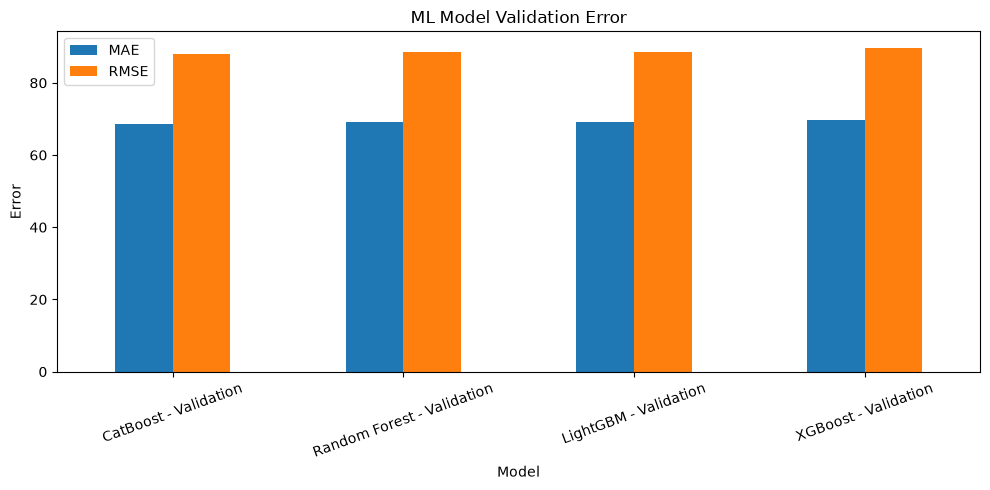

In [18]:
import matplotlib.pyplot as plt

validation_comparison.plot(
    x="Model",
    y=["MAE", "RMSE"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("ML Model Validation Error")
plt.ylabel("Error")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 11. XGBoost feature importance

In [19]:
importances = xgb_model.feature_importances_

metadata = joblib.load(
    models_dir / "feature_metadata.pkl"
)

feature_columns = metadata["feature_columns"]
categorical_features = metadata["categorical_features"]
numerical_features = metadata["numerical_features"]

# Reconstruct names in the same order used by the notebook:
# numerical features first, then one-hot encoded categorical features.
encoded_names = numerical_features.copy()

encoder = joblib.load(
    models_dir / "categorical_encoder.pkl"
)

encoded_names.extend(
    encoder.get_feature_names_out(categorical_features).tolist()
)

importance_df = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

importance_df.head(20)

,Feature,Importance
0,Inventory Level,0.092091
30,Product ID_P0007,0.019374
35,Product ID_P0012,0.018424
32,Product ID_P0009,0.018118
42,Product ID_P0019,0.017825
24,Product ID_P0001,0.017746
43,Product ID_P0020,0.017553
39,Product ID_P0016,0.017268
27,Product ID_P0004,0.017225
34,Product ID_P0011,0.017067


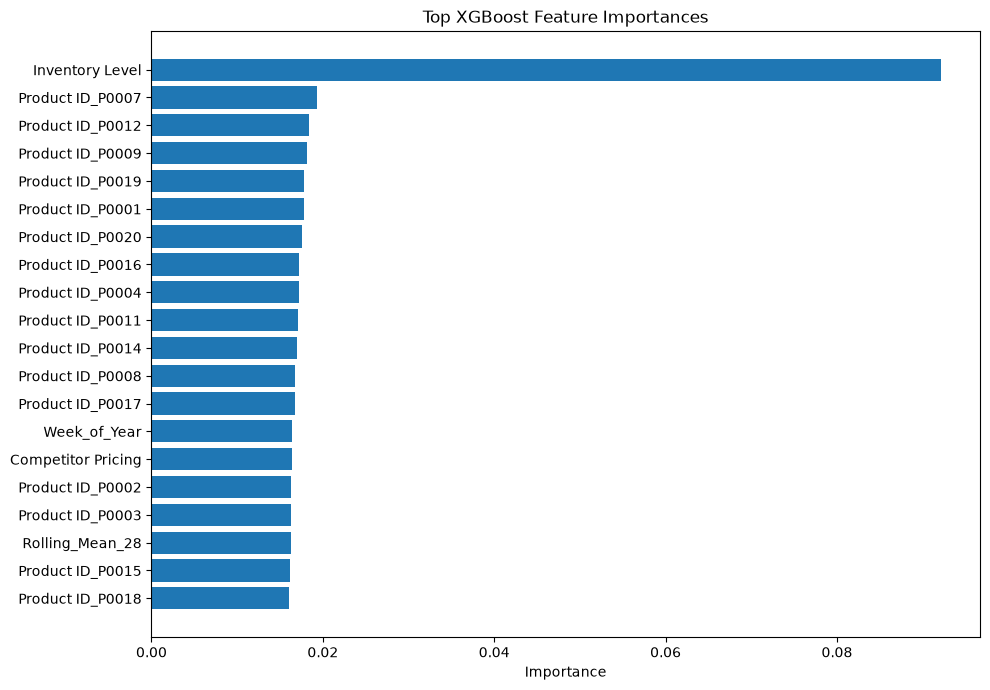

In [20]:
top_features = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top XGBoost Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 12. Save trained models

We save the models so the best candidate can later be integrated into FastAPI.

In [21]:
joblib.dump(
    rf_model,
    models_dir / "random_forest_demand_model.pkl"
)

joblib.dump(
    xgb_model,
    models_dir / "xgboost_demand_model.pkl"
)

if lgbm_model is not None:
    joblib.dump(
        lgbm_model,
        models_dir / "lightgbm_demand_model.pkl"
    )

if cat_model is not None:
    joblib.dump(
        cat_model,
        models_dir / "catboost_demand_model.pkl"
    )

print("Available trained models saved successfully.")

Available trained models saved successfully.


# Next step

Do **not** immediately deploy the first model.

Next we should:

1. Compare ML results against the classical time-series results.
2. Select the strongest candidate using validation MAE/RMSE.
3. Tune its hyperparameters.
4. Evaluate the tuned model once on the untouched test set.
5. Save the final model.
6. Add MLflow experiment tracking.
7. Integrate the final model into FastAPI.

The final deployment should use the **same feature engineering + encoder + trained model** pipeline used during training.